In [5]:
import os
import sys

from getpass import getpass

token = getpass("GitHub PAT: ")
os.environ["GITHUB_TOKEN"] = token

!git clone https://$GITHUB_TOKEN@github.com/Hanh3103/BA_USDependency.git

%cd /content/BA_USDependency

!git checkout Tool

current_dir = os.getcwd()
repo_root = current_dir
while not os.path.exists(os.path.join(repo_root, "app")):
    parent = os.path.dirname(repo_root)
    if parent == repo_root:  # Reached system root without finding it
        repo_root = os.path.abspath(os.path.join(current_dir, "..", "..", ".."))
        break
    repo_root = parent

src_path = os.path.abspath("src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

GitHub PAT: ··········
fatal: destination path 'BA_USDependency' already exists and is not an empty directory.
/content/BA_USDependency
Already on 'Tool'
Your branch is up to date with 'origin/Tool'.


In [2]:
!git config --global user.email "thiminhhanhnguyen.95@gmail.com"
!git config --global user.name "Hanh3103"

In [ ]:
!git pull

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 432 bytes | 144.00 KiB/s, done.
From https://github.com/Hanh3103/BA_USDependency
   6db2f9f..c3c0f5e  Tool       -> origin/Tool
Updating 6db2f9f..c3c0f5e
Fast-forward
 app/stages/annotation.py | 1 +
 1 file changed, 1 insertion(+)


In [43]:
!git add .
!git commit -m "Add RQ2 eval results: llama3.1:8b + qwen3:8b, annotation"
!git push https://$GITHUB_TOKEN@github.com/Hanh3103/BA_USDependency.git Tool

hint: You've added another git repository inside your current repository.
hint: Clones of the outer repository will not contain the contents of
hint: the embedded repository and will not know how to obtain it.
hint: If you meant to add a submodule, use:
hint: 
hint: 	git submodule add <url> BA_USDependency
hint: 
hint: If you added this path by mistake, you can remove it from the
hint: index with:
hint: 
hint: 	git rm --cached BA_USDependency
hint: 
hint: See "git help submodule" for more information.
[Tool 8fd044c] Add RQ2 eval results: llama3.1:8b + qwen3:8b, annotation
 5 files changed, 148 insertions(+), 147 deletions(-)
 create mode 160000 BA_USDependency
Enumerating objects: 15, done.
Counting objects: 100% (15/15), done.
Delta compression using up to 2 threads
Compressing objects: 100% (9/9), done.
Writing objects: 100% (9/9), 2.78 KiB | 2.78 MiB/s, done.
Total 9 (delta 6), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (6/6), completed with 4 local objects.
To

In [6]:
print("Repo Root:", repo_root)
print("App Path added to sys.path:", src_path)

Repo Root: /content/BA_USDependency
App Path added to sys.path: /content/BA_USDependency/src


In [7]:
!pip install -r requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.4/109.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.3/472.3 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.5/71.5 kB 7.7 MB/s eta 0:00:00
  Attempting uninstall: uvicorn
    Found existing installation: uvicorn 0.52.4
    Uninstalling uvicorn-0.52.4:
      Successfully uninstalled uvicorn-0.52.4
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.46.5
    Uninstalling pydantic_core-2.46.5:
      Successfully uninstalled pydantic_core-2.46.5
  Attempting uninstall: starl

In [8]:
# 2. Re-create the .env file with required settings
env_content = """OLLAMA_BASE_URL=http://localhost:11434
OLLAMA_API_KEY=ollama
OLLAMA_MODELS=qwen3:8b,llama3.1:8b
OLLAMA_TEMPERATURE=0.0
OLLAMA_TOP_P=0.1
OLLAMA_NUM_PREDICT=2048
OLLAMA_NUM_CTX=8192
OLLAMA_KEEP_ALIVE=20m
OLLAMA_THINK=false
OLLAMA_FORMAT=json
"""

env_target = os.path.join(repo_root, ".env")
with open(env_target, "w") as f:
    f.write(env_content.strip())

print(f"Wrote .env to: {env_target}")

Wrote .env to: /content/BA_USDependency/.env


In [9]:
!apt-get update -qq
!apt-get install -y zstd

# 1. Install Ollama binary
!curl -fsSL https://ollama.com/install.sh | sh

# 2. Launch background service with GPU and parallel execution settings
import subprocess
import time

env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"
env["OLLAMA_KEEP_ALIVE"] = "-1"      # Keep models pinned in VRAM
env["OLLAMA_NUM_PARALLEL"] = "4"     # Enable parallel pipeline processing

ollama_process = subprocess.Popen(["ollama", "serve"], env=env)
time.sleep(5)  # Wait for server startup

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 71 not upgraded.
Need to get 644 kB of archives.
After this operation, 1,845 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 zstd amd64 1.5.5+dfsg2-2build1.1 [644 kB]
Fetched 644 kB in 1s (502 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 126952 files and directories currently installed.)
Preparing to unpack .../zs

In [10]:
from config import settings
import subprocess

for model in settings.models:
    model = model.strip()
    print(f"Pulling {model}...")
    result = subprocess.run(["ollama", "pull", model], capture_output=True, text=True)
    if result.returncode != 0:
        print(f"FAILED to pull {model}:\n{result.stderr}")
    else:
        print(f"OK: {model}")

ENV path: /content/BA_USDependency/.env
ENV exists: True
ENV values: OrderedDict({'OLLAMA_BASE_URL': 'http://localhost:11434', 'OLLAMA_API_KEY': 'ollama', 'OLLAMA_MODELS': 'qwen3:8b,llama3.1:8b', 'OLLAMA_TEMPERATURE': '0.0', 'OLLAMA_TOP_P': '0.1', 'OLLAMA_NUM_PREDICT': '2048', 'OLLAMA_NUM_CTX': '8192', 'OLLAMA_KEEP_ALIVE': '20m', 'OLLAMA_THINK': 'false', 'OLLAMA_FORMAT': 'json'})
Pulling qwen3:8b...
OK: qwen3:8b
Pulling llama3.1:8b...
OK: llama3.1:8b


In [11]:
!ollama list

NAME           ID              SIZE      MODIFIED           
llama3.1:8b    46e0c10c039e    4.9 GB    About a minute ago    
qwen3:8b       500a1f067a9f    5.2 GB    2 minutes ago         


In [12]:
import json
from pathlib import Path
import pandas as pd
import spacy
from IPython.display import display

In [13]:
RAW_PATH = Path(repo_root) / "eval_with_colab" / "annotation" / "raw" / "test_1.txt"
GT_PATH = Path(repo_root)/ "eval_with_colab"/ "annotation"/ "baseline" / "20US_baseline.json"

if os.path.exists(GT_PATH):
    print("Ground truth file found successfully!")
else:
    print("Error: Ground truth file not found. Check path.")

if os.path.exists(RAW_PATH):
    print("Raw file found successfully!")
else:
    print("Error: Raw file not found. Check path.")


PREDICTION_DIR = Path(repo_root) / "eval_with_colab" / "annotation" / "prediction"
EVAL_DIR = Path(repo_root) / "eval_with_colab" / "annotation" / "evaluation"
PREDICTION_DIR.parent.mkdir(parents=True, exist_ok=True)
EVAL_DIR.parent.mkdir(parents=True, exist_ok=True)

Ground truth file found successfully!
Raw file found successfully!


In [14]:
MODES = ["strict", "included", "relaxed"]
QUALIFIER_POS_TAGS = {"ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "PUNCT", "SCONJ", "X"}

In [15]:
nlp = spacy.load("en_core_web_sm")

In [20]:
def normalize_story_text(text: str) -> str:
    return " ".join(str(text).strip().casefold().split())


raw_stories = [
    line.strip()
    for line in RAW_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

baseline = json.loads(
    GT_PATH.read_text(encoding="utf-8")
)

baseline_stories = [story["Text"] for story in baseline]

print("Raw stories:", len(raw_stories))
print("Baseline stories:", len(baseline_stories))

assert len(raw_stories) == len(baseline_stories), (
    "Raw and baseline have different story counts."
)

mismatches = []

for position, (raw_text, baseline_text) in enumerate(
    zip(raw_stories, baseline_stories),
    start=1,
):
    if normalize_story_text(raw_text) != normalize_story_text(baseline_text):
        mismatches.append(
            {
                "position": position,
                "raw": raw_text,
                "baseline": baseline_text,
            }
        )

if mismatches:
    print(f"FAILED: {len(mismatches)} text/order mismatches")
    for item in mismatches:
        print(f"\nPosition {item['position']}")
        print("RAW:     ", item["raw"])
        print("BASELINE:", item["baseline"])
else:
    print("PASS: Raw and baseline story texts match in the same order.")

Raw stories: 20
Baseline stories: 20
PASS: Raw and baseline story texts match in the same order.


**Generate Annotated US**

In [21]:
import json
from pathlib import Path
from stages.annotation import annotate
from utils.file_parser import load_raw_stories

In [22]:
def generate_predictions_from_raw(
    raw_file_path: Path, model_name: str, filename: str, mode: str = "sequential"
):
    output_path = PREDICTION_DIR / filename
    meta_path = PREDICTION_DIR / f"{Path(filename).stem}_meta.json"
    stories = load_raw_stories(str(raw_file_path))

    annotated_results = []
    meta_log = []
    failed_log = []

    for i, story_text in enumerate(stories):
        story_id = f"US-{i+1:03d}"
        outcome = annotate(
            user_story=story_text,
            story_id=story_id,
            model=model_name,
            mode=mode,
            max_retries=2,
        )
        if outcome:
            annotated_results.append(outcome["annotation"])
            meta_log.append({
                "story_id": outcome["story_id"],
                "runtime_sec": outcome["runtime_sec"],
                "attempts": outcome["attempts"],
                "model": model_name,
                "mode": mode,
            })
        else:
            failed_log.append({
                "story_id": story_id,
                "story_text": story_text,
                "model": model_name,
                "mode": mode,
            })

    # Save annoatuíon result to to PREDICTION_DIR
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(annotated_results, f, indent=2, ensure_ascii=False)

    # save meta data into file
    if meta_log:
        times = [r["runtime_sec"] for r in meta_log]
        {
        "model": model_name,
        "mode": mode,
        "raw_file": str(raw_file_path),
        "n_stories_input": len(stories),
        "n_stories_annotated": len(annotated_results),
        "n_stories_failed": len(failed_log),
        "per_story": meta_log,
        "failed_stories": failed_log,
    }["runtime_summary"] = {
            "total_sec": round(sum(times), 3),
            "avg_sec": round(sum(times) / len(times), 3),
            "min_sec": round(min(times), 3),
            "max_sec": round(max(times), 3),
        }
        print(f"Runtime — total: {sum(times):.1f}s, avg/story: {sum(times)/len(times):.2f}s, "
              f"min: {min(times):.2f}s, max: {max(times):.2f}s")

    if failed_log:
        print(f"Failed to annotate {len(failed_log)} stories: "
              f"{[f['story_id'] for f in failed_log]}")

    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump({
        "model": model_name,
        "mode": mode,
        "raw_file": str(raw_file_path),
        "n_stories_input": len(stories),
        "n_stories_annotated": len(annotated_results),
        "n_stories_failed": len(failed_log),
        "per_story": meta_log,
        "failed_stories": failed_log,
    }, f, indent=2, ensure_ascii=False)

    print(f"Saved {len(annotated_results)} predictions to {output_path}")
    print(f"Saved run metadata to {meta_path}")
    return annotated_results, output_path, {
        "model": model_name,
        "mode": mode,
        "raw_file": str(raw_file_path),
        "n_stories_input": len(stories),
        "n_stories_annotated": len(annotated_results),
        "n_stories_failed": len(failed_log),
        "per_story": meta_log,
        "failed_stories": failed_log,
    }

In [23]:
llama_results, llama_PRED_PATH, llama_run_meta= generate_predictions_from_raw(
    raw_file_path=RAW_PATH,
    model_name="llama3.1:8b",
    filename="llama_pred_ann.json",
    mode="sequential",
)

llama_meta_df = pd.DataFrame(llama_run_meta["per_story"])
llama_failed_df = pd.DataFrame(llama_run_meta["failed_stories"])

display(llama_meta_df)
if not llama_failed_df.empty:
    display(llama_failed_df)

US-001 annotated in 100.5s (attempt 1, mode=sequential)
US-002 annotated in 6.7s (attempt 1, mode=sequential)
US-003 annotated in 7.6s (attempt 1, mode=sequential)
US-004 annotated in 6.9s (attempt 1, mode=sequential)
US-005 annotated in 6.6s (attempt 1, mode=sequential)
US-006 annotated in 6.1s (attempt 1, mode=sequential)
US-007 annotated in 6.9s (attempt 1, mode=sequential)
US-008 annotated in 5.8s (attempt 1, mode=sequential)
US-009 annotated in 7.7s (attempt 1, mode=sequential)
US-010 annotated in 5.0s (attempt 1, mode=sequential)
US-011 annotated in 7.4s (attempt 1, mode=sequential)
US-012 annotated in 7.4s (attempt 1, mode=sequential)
US-013 annotated in 7.9s (attempt 1, mode=sequential)
US-014 annotated in 8.9s (attempt 1, mode=sequential)
US-015 annotated in 8.0s (attempt 1, mode=sequential)
US-016 annotated in 7.7s (attempt 1, mode=sequential)
US-017 annotated in 8.4s (attempt 1, mode=sequential)
US-018 annotated in 5.7s (attempt 1, mode=sequential)
US-019 annotated in 7.2s (

,story_id,runtime_sec,attempts,model,mode
0,US-001,100.521,1,llama3.1:8b,sequential
1,US-002,6.673,1,llama3.1:8b,sequential
2,US-003,7.566,1,llama3.1:8b,sequential
3,US-004,6.874,1,llama3.1:8b,sequential
4,US-005,6.613,1,llama3.1:8b,sequential
5,US-006,6.084,1,llama3.1:8b,sequential
6,US-007,6.886,1,llama3.1:8b,sequential
7,US-008,5.762,1,llama3.1:8b,sequential
8,US-009,7.669,1,llama3.1:8b,sequential
9,US-010,4.992,1,llama3.1:8b,sequential


In [24]:
qwen_results, qwen_PRED_PATH, qwen_run_meta= generate_predictions_from_raw(
    raw_file_path=RAW_PATH,
    model_name="qwen3:8b",
    filename="qwen_pred_ann.json",
    mode="sequential",
)

qwen_meta_df = pd.DataFrame(qwen_run_meta["per_story"])
qwen_failed_df = pd.DataFrame(qwen_run_meta["failed_stories"])

display(qwen_meta_df)
if not qwen_failed_df.empty:
    display(qwen_failed_df)

US-001 annotated in 58.5s (attempt 1, mode=sequential)
US-002 annotated in 8.4s (attempt 1, mode=sequential)
US-003 annotated in 11.4s (attempt 1, mode=sequential)
US-004 annotated in 7.3s (attempt 1, mode=sequential)
US-005 annotated in 8.2s (attempt 1, mode=sequential)
US-006 annotated in 8.0s (attempt 1, mode=sequential)
US-007 annotated in 7.0s (attempt 1, mode=sequential)
US-008 annotated in 6.6s (attempt 1, mode=sequential)
US-009 annotated in 10.2s (attempt 1, mode=sequential)
US-010 annotated in 6.5s (attempt 1, mode=sequential)
US-011 annotated in 7.1s (attempt 1, mode=sequential)
US-012 annotated in 7.5s (attempt 1, mode=sequential)
US-013 annotated in 8.7s (attempt 1, mode=sequential)
US-014 annotated in 9.5s (attempt 1, mode=sequential)
US-015 annotated in 8.8s (attempt 1, mode=sequential)
US-016 annotated in 7.8s (attempt 1, mode=sequential)
US-017 annotated in 7.7s (attempt 1, mode=sequential)
US-018 annotated in 7.8s (attempt 1, mode=sequential)
US-019 annotated in 6.2s 

,story_id,runtime_sec,attempts,model,mode
0,US-001,58.469,1,qwen3:8b,sequential
1,US-002,8.438,1,qwen3:8b,sequential
2,US-003,11.391,1,qwen3:8b,sequential
3,US-004,7.260,1,qwen3:8b,sequential
4,US-005,8.190,1,qwen3:8b,sequential
5,US-006,7.973,1,qwen3:8b,sequential
6,US-007,6.979,1,qwen3:8b,sequential
7,US-008,6.582,1,qwen3:8b,sequential
8,US-009,10.224,1,qwen3:8b,sequential
9,US-010,6.460,1,qwen3:8b,sequential


In [25]:
llama_meta_df["model"] = "llama3.1:8b"
qwen_meta_df["model"] = "qwen3:8b"

llama_stats = llama_meta_df["runtime_sec"].agg(["mean", "min", "max", "sum", "count"]).round(3)
qwen_stats = qwen_meta_df["runtime_sec"].agg(["mean", "min", "max", "sum", "count"]).round(3)

runtime_compare = pd.DataFrame({
    "llama3.1:8b": llama_stats,
    "qwen3:8b": qwen_stats,
})
display(runtime_compare)

,llama3.1:8b,qwen3:8b
mean,11.863,10.557
min,4.992,6.220
max,100.521,58.469
sum,237.261,211.137
count,20.000,20.000


In [26]:
print(llama_meta_df["runtime_sec"].describe())
print(qwen_meta_df["runtime_sec"].describe())

count     20.000000
mean      11.863050
std       20.893576
min        4.992000
25%        6.658000
50%        7.406000
75%        7.917750
max      100.521000
Name: runtime_sec, dtype: float64
count    20.000000
mean     10.556850
std      11.347701
min       6.220000
25%       7.230500
50%       7.887000
75%       8.708750
max      58.469000
Name: runtime_sec, dtype: float64


/tmp/ipykernel_1965/1947277636.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_1965/1947277636.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


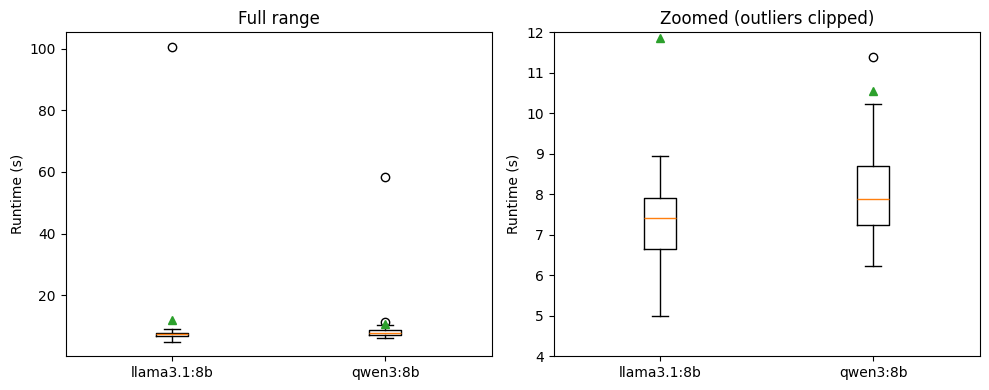

llama3.1:8b outliers:
  story_id  runtime_sec
0   US-001      100.521

qwen3:8b outliers:
  story_id  runtime_sec
0   US-001       58.469
2   US-003       11.391



In [27]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax in axes:
    ax.boxplot(
        [llama_meta_df["runtime_sec"], qwen_meta_df["runtime_sec"]],
        labels=["llama3.1:8b", "qwen3:8b"],
        showmeans=True,
    )
    ax.set_ylabel("Runtime (s)")

axes[0].set_title("Full range")
axes[1].set_ylim(4, 12)   # tighter zoom around the box/whisker range
axes[1].set_title("Zoomed (outliers clipped)")

plt.tight_layout()
plt.show()

# Report outliers separately
for name, df in [("llama3.1:8b", llama_meta_df), ("qwen3:8b", qwen_meta_df)]:
    q1, q3 = df["runtime_sec"].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = df[df["runtime_sec"] > q3 + 1.5 * iqr]
    if not outliers.empty:
        print(f"{name} outliers:\n{outliers[['story_id', 'runtime_sec']]}\n")

**Evaluation**


1. **Load Ground Truth and Predictions**: Load the ground truth and predictions from JSON files.
2. **Match Stories by Text**: Match stories from ground truth and predictions based on their text content.

In [28]:
def load_annotated_stories(path: Path) -> dict:
    print(path)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def matching_stories_by_text(gt_stories: list[dict], pred_stories: list[dict]):
    remaining_pred_stories = list(pred_stories)
    matched_gt, match_pred = [], []

    for gt_story in gt_stories:
        gt_text = gt_story["Text"].strip()

        matched_index = next(
            (i for i,p in enumerate(remaining_pred_stories) if p["Text"] == gt_text), None
        )

        if matched_index is not None:
            matched_gt.append(gt_story)
            match_pred.append(remaining_pred_stories.pop(matched_index))

    extract_texts = {g["Text"].strip() for g in matched_gt}
    unmatched_gt = [g["Text"][:60] for g in gt_stories if g["Text"].strip() not in extract_texts]
    unmatched_pred = [p["Text"][:60] for p in remaining_pred_stories]

    return matched_gt, match_pred, unmatched_gt, unmatched_pred


In [29]:
gt_raw, pred_raw = None, None
try:
    gt_raw = load_annotated_stories(GT_PATH)
except FileNotFoundError:
    print(f"Ground truth file not found at {GT_PATH}. Please ensure the file exists.")

# try:
#     llama_pred_raw = load_annotated_stories(llama_PRED_PATH)
# except FileNotFoundError:
#     print(f"Predictions file not found at {llama_PRED_PATH}. Please ensure the file exists.")
# try:
#     qwen_pred_raw = load_annotated_stories(qwen_PRED_PATH)
# except FileNotFoundError:
#     print(f"Predictions file not found at {llama_PRED_PATH}. Please ensure the file exists.")


llama_gt, llama_pred, llama_unmatched_gt, llama_unmatched_pred = matching_stories_by_text(gt_raw, llama_results)
print(f"[llama] Aligned {len(llama_gt)} / {len(llama_pred)} stories.")
if llama_unmatched_gt:
    print(f"[llama] WARNING: Unmatched gold stories: {llama_unmatched_gt}")
if llama_unmatched_pred:
    print(f"[llama] WARNING: Unmatched prediction stories: {llama_unmatched_pred}")

qwen_gt, qwen_pred, qwen_unmatched_gt, qwen_unmatched_pred = matching_stories_by_text(gt_raw, qwen_results)
print(f"[qwen] Aligned {len(qwen_gt)} / {len(qwen_pred)} stories.")
if qwen_unmatched_gt:
    print(f"[qwen] WARNING: Unmatched gold stories: {qwen_unmatched_gt}")
if qwen_unmatched_pred:
    print(f"[qwen] WARNING: Unmatched prediction stories: {qwen_unmatched_pred}")

/content/BA_USDependency/eval_with_colab/annotation/baseline/20US_baseline.json
[llama] Aligned 20 / 20 stories.
[qwen] Aligned 20 / 20 stories.


### String-level matching rules

In [30]:
def normalize(text:str) -> str:
    """Normalize text for comparison: lowercase and strip whitespace."""
    return text.lower().strip()

#----------Extract---------------------#
def is_exact_match(phrase_a:str, phrase_b:str) -> bool:
    """True if the two phrases are identical after normalization (case-insensitive, whitespace-trimmed)."""
    return normalize(phrase_a) == normalize(phrase_b)
#----------Included---------------------#
def is_included_match(phrase_a: str, phrase_b: str) -> bool:
    """True if the two phrases have the same word count and differ only by one pair of words where each is a substring of the other (e.g. a singular/plural pair), with every other word identical."""
    words_list_a = normalize(phrase_a).split()
    words_list_b = normalize(phrase_b).split()
    if len(words_list_a) != len(words_list_b):
        return False

    for word_x in words_list_a:
        for word_y in words_list_b:
            if word_x in word_y or word_y in word_x:
                rest_words_list_a = words_list_a.copy()
                rest_words_list_a.remove(word_x)

                rest_words_list_b = words_list_b.copy()
                rest_words_list_b.remove(word_y)
                if rest_words_list_a == rest_words_list_b:
                    return True
    return False

#------------------Relaxed-------------------#
def strip_qualifiers(text: str) -> str:
    """
    Drop function/qualifier words (POS-tagged via spaCy) and return what remains, e.g. "many datasets" -> "datasets".
    """
    doc = nlp(text)
    kept_words = []
    for token in doc:
        if token.pos_ not in QUALIFIER_POS_TAGS:
            kept_words.append(token.text)

    return " ".join(kept_words)


def is_relaxed_match(phrase_a: str, phrase_b: str) -> bool:
    if is_exact_match(phrase_a, phrase_b):
        return True
    return normalize(strip_qualifiers(phrase_a)) == normalize(strip_qualifiers(phrase_b))


### Pair-level rules

In [31]:
def compare_node_list(gt_items, pred_items, mode):
    """Compare two lists of items (spans) and return true positives, false positives, and false negatives based on the specified matching mode."""
    gt_items = list(gt_items) # copy list
    true_positives = []
    remain_pred = []

    # Step 1 exact match
    for item in pred_items:
        match_index = None
        for i in range(len(gt_items)):
            if is_exact_match(item, gt_items[i]):
                match_index = i
                break

        if match_index is not None:
            matched_item = gt_items.pop(match_index)
            true_positives.append(matched_item)
        else:
            remain_pred.append(item)

    if mode == "strict":
        false_positives = remain_pred
        false_negatives = gt_items
        return true_positives, false_positives, false_negatives


    false_positives = []
    for predicted_item in remain_pred:
        match_index = None
        for i in range(len(gt_items)):
            if mode == "included":
                is_match = is_included_match(predicted_item, gt_items[i])
            else:  # relaxed
                is_match = is_relaxed_match(predicted_item, gt_items[i])
            if is_match:
                match_index = i
                break

        if match_index is not None:
            matched_item = gt_items.pop(match_index)
            true_positives.append(matched_item)
        else:
            false_positives.append(predicted_item)

    false_negatives = gt_items
    return true_positives, false_positives, false_negatives


In [32]:
def compare_edge_list(gt_edges, pred_edges, mode):
    """Compare two lists of edges (pairs) and return true positives, false positives, and false negatives based on the specified matching mode."""
    gt_edges = [list(pair) for pair in gt_edges]  # copy
    true_positives = []
    leftover_predictions = []

    # step 1 exact match
    for predicted_pair in pred_edges:
        match_index = None
        for i in range(len(gt_edges)):
            gold_pair = gt_edges[i]
            first_matches = is_exact_match(predicted_pair[0], gold_pair[0])
            second_matches = is_exact_match(predicted_pair[1], gold_pair[1])
            if first_matches and second_matches:
                match_index = i
                break

        if match_index is not None:
            matched_pair = gt_edges.pop(match_index)
            true_positives.append(matched_pair)
        else:
            leftover_predictions.append(predicted_pair)

    if mode == "strict":
        false_positives = leftover_predictions
        false_negatives = gt_edges
        return true_positives, false_positives, false_negatives

    # Step 2 fall back
    false_positives = []
    for predicted_pair in leftover_predictions:
        match_index = None
        for i in range(len(gt_edges)):
            gold_pair = gt_edges[i]
            if mode == "included":
                first_matches = is_included_match(predicted_pair[0], gold_pair[0])
                second_matches = is_included_match(predicted_pair[1], gold_pair[1])
            else:  # relaxed
                first_matches = is_relaxed_match(predicted_pair[0], gold_pair[0])
                second_matches = is_relaxed_match(predicted_pair[1], gold_pair[1])

            if first_matches and second_matches:
                match_index = i
                break

        if match_index is not None:
            matched_pair = gt_edges.pop(match_index)
            true_positives.append(matched_pair)
        else:
            false_positives.append(predicted_pair)

    false_negatives = gt_edges
    return true_positives, false_positives, false_negatives


In [33]:
def precision_recall_f1(true_positive_count: int, false_positive_count: int, false_negative_count: int):
    """Compute precision, recall, and F1 score based on counts of true positives, false positives, and false negatives."""
    precision = true_positive_count / (true_positive_count + false_positive_count) \
        if (true_positive_count + false_positive_count) else 0.0
    recall = true_positive_count / (true_positive_count + false_negative_count) \
        if (true_positive_count + false_negative_count) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return precision, recall, f1

In [34]:
SPAN_FIELD_NAMES = ["Persona", "GoalAction", "BenefitAction", "GoalEntity", "BenefitEntity", "benefit"]
PAIR_FIELD_NAMES = ["triggers", "targets", "contains"]

def getter_field_items(annotated_story, field_name):
    if field_name in ("GoalAction", "BenefitAction"):
        return annotated_story.get("Action", {}).get(field_name, [])
    elif field_name in ("GoalEntity", "BenefitEntity"):
        return annotated_story.get("Entity", {}).get(field_name, [])
    elif field_name in SPAN_FIELD_NAMES:
        return annotated_story.get(field_name, [])
    elif field_name in PAIR_FIELD_NAMES:
        return annotated_story.get(field_name, [])
    else:
        raise ValueError(f"Unknown field name: {field_name}")


In [35]:
def evaluate_field(gt_stories, predicted_stories, field_name, field_type, mode):
    """Evaluate a specific field across all stories and return overall and per-story precision, recall, and F1 scores."""
    total_true_positives = 0
    total_false_positives = 0
    total_false_negatives = 0
    per_story_scores = []

    for i in range(len(gt_stories)):
        gt_story = gt_stories[i]
        predicted_story = predicted_stories[i]

        gt_items = getter_field_items(gt_story, field_name)
        predicted_items = getter_field_items(predicted_story, field_name)

        if field_type == "span":
            true_positives, false_positives, false_negatives = compare_node_list(gt_items, predicted_items, mode)
        else:  # "pair"
            true_positives, false_positives, false_negatives = compare_edge_list(gt_items, predicted_items, mode)

        total_true_positives += len(true_positives)
        total_false_positives += len(false_positives)
        total_false_negatives += len(false_negatives)

        story_precision, story_recall, story_f1 = precision_recall_f1(
            len(true_positives), len(false_positives), len(false_negatives)
        )
        per_story_scores.append({"precision": story_precision, "recall": story_recall, "f1": story_f1})

    precision, recall, f1 = precision_recall_f1(
        total_true_positives, total_false_positives, total_false_negatives
    )
    overall_result = {
        "tp": total_true_positives,
        "fp": total_false_positives,
        "fn": total_false_negatives,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }
    return overall_result, per_story_scores


In [36]:
def score_predictions(gt_stories, pred_stories):
    """Score predictions against ground truth for all fields and modes, returning overall and per-story results."""
    results = {}
    per_story = {}

    if pred_stories is None:
        return results, per_story

    for mode in MODES:
        results[mode] = {}
        per_story[mode] = {}

        for field_name in SPAN_FIELD_NAMES:
            overall_result, story_scores = evaluate_field(gt_stories, pred_stories, field_name, "span", mode)
            results[mode][field_name] = overall_result
            per_story[mode][field_name] = story_scores

        for field_name in PAIR_FIELD_NAMES:
            overall_result, story_scores = evaluate_field(gt_stories, pred_stories, field_name, "pair", mode)
            results[mode][field_name] = overall_result
            per_story[mode][field_name] = story_scores

    return results, per_story

In [37]:
llama_results_scores, llama_per_story = score_predictions(llama_gt, llama_pred)
qwen_results_scores, qwen_per_story = score_predictions(qwen_gt, qwen_pred)

print("Done. Fields scored: " + str(SPAN_FIELD_NAMES + PAIR_FIELD_NAMES))

Done. Fields scored: ['Persona', 'GoalAction', 'BenefitAction', 'GoalEntity', 'BenefitEntity', 'benefit', 'triggers', 'targets', 'contains']


In [38]:
def build_summary(results_scores):
    """Build a summary DataFrame of F1 scores for each field and mode."""
    all_field_names = SPAN_FIELD_NAMES + PAIR_FIELD_NAMES

    summary_rows = []
    for field_name in all_field_names:
        strict_f1 = results_scores["strict"][field_name]["f1"]
        inclusion_f1 = results_scores["included"][field_name]["f1"]
        relaxed_f1 = results_scores["relaxed"][field_name]["f1"]
        summary_rows.append({
            "field": field_name,
            "strict_f1": strict_f1,
            "included_f1": inclusion_f1,
            "relaxed_f1": relaxed_f1,
        })

    summary = pd.DataFrame(summary_rows)
    summary = summary.set_index("field")
    summary = summary.round(3)
    return summary

In [39]:
llama_summary = build_summary(llama_results_scores)
qwen_summary = build_summary(qwen_results_scores)

print("llama3.1:8b")
display(llama_summary)

print("qwen3:8b")
display(qwen_summary)

llama3.1:8b


,strict_f1,included_f1,relaxed_f1
field,,,
Persona,1.000,1.000,1.000
GoalAction,0.721,0.787,0.787
BenefitAction,0.634,0.634,0.732
GoalEntity,0.661,0.661,0.713
BenefitEntity,0.689,0.689,0.711
benefit,0.964,0.964,0.969
triggers,0.698,0.762,0.762
targets,0.317,0.317,0.403
contains,0.000,0.000,0.000


qwen3:8b


,strict_f1,included_f1,relaxed_f1
field,,,
Persona,1.000,1.000,1.000
GoalAction,0.873,0.873,0.873
BenefitAction,0.698,0.698,0.884
GoalEntity,0.748,0.748,0.748
BenefitEntity,0.731,0.731,0.774
benefit,0.993,0.993,0.993
triggers,0.873,0.873,0.873
targets,0.496,0.496,0.539
contains,0.051,0.051,0.051


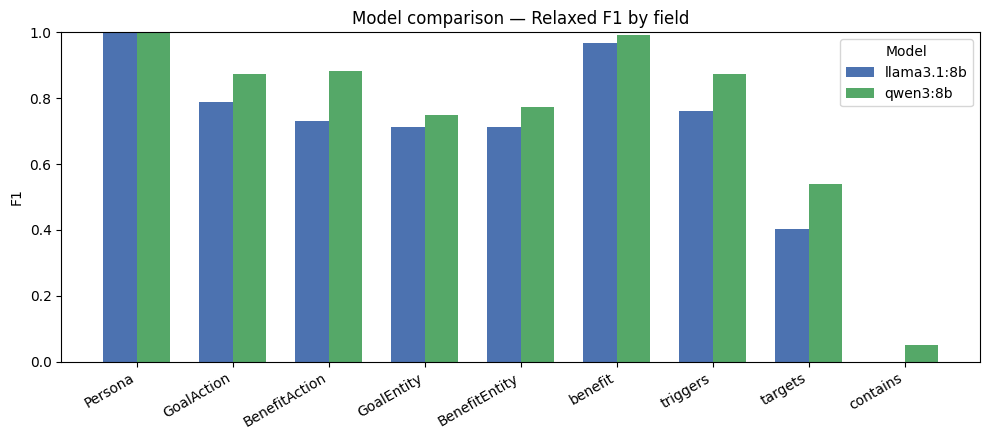

In [40]:
import numpy as np

def plot_model_comparison(llama_summary, qwen_summary, mode_column="relaxed_f1"):
    field_names = llama_summary.index.tolist()
    x_positions = np.arange(len(field_names))
    bar_width = 0.35

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x_positions - bar_width/2, llama_summary[mode_column], bar_width,
           label="llama3.1:8b", color="#4C72B0")
    ax.bar(x_positions + bar_width/2, qwen_summary[mode_column], bar_width,
           label="qwen3:8b", color="#55A868")

    ax.set_xticks(x_positions)
    ax.set_xticklabels(field_names, rotation=30, ha="right")
    ax.set_ylabel("F1")
    ax.set_ylim(0, 1)
    ax.set_title(f"Model comparison — {mode_column.replace('_f1', '').capitalize()} F1 by field")
    ax.legend(title="Model")
    plt.tight_layout()
    plt.show()

plot_model_comparison(llama_summary, qwen_summary, mode_column="relaxed_f1")

In [41]:
def build_story_df(gt_stories, per_story_scores, run_results, run_meta):
    """Build a DataFrame summarizing average F1 scores and runtime for each story."""
    all_field_names = SPAN_FIELD_NAMES + PAIR_FIELD_NAMES

    # story_id -> runtime lookup, joined by Text (only stable shared key)
    runtime_by_text = {
        annotation["Text"].strip(): meta_row
        for annotation, meta_row in zip(run_results, run_meta["per_story"])
    }

    story_rows = []
    for story_index in range(len(gt_stories)):
        gt_story = gt_stories[story_index]

        field_f1_scores = []
        for field_name in all_field_names:
            story_score = per_story_scores["relaxed"][field_name][story_index]
            field_f1_scores.append(story_score["f1"])

        average_f1 = sum(field_f1_scores) / len(field_f1_scores)

        meta_row = runtime_by_text.get(gt_story["Text"].strip(), {})

        story_rows.append({
            "US_text": gt_story["Text"],
            "avg_f1_relaxed": average_f1,
            "runtime_sec": meta_row.get("runtime_sec"),
            "attempts": meta_row.get("attempts"),
        })

    story_df = pd.DataFrame(story_rows)
    story_df = story_df.sort_values("avg_f1_relaxed")
    story_df = story_df.reset_index(drop=True)
    return story_df


llama_story_df = build_story_df(llama_gt, llama_per_story, llama_results, llama_run_meta)
qwen_story_df = build_story_df(qwen_gt, qwen_per_story, qwen_results, qwen_run_meta)

In [42]:
print("llama3.1:8b — hardest stories (lowest F1):")
display(llama_story_df.sort_values("avg_f1_relaxed").head(5)[["US_text", "avg_f1_relaxed"]])

print("qwen3:8b — hardest stories (lowest F1):")
display(qwen_story_df.sort_values("avg_f1_relaxed").head(5)[["US_text", "avg_f1_relaxed"]])

llama3.1:8b — hardest stories (lowest F1):


,US_text,avg_f1_relaxed
0,"As a traveler, I want to import a location fro...",0.503202
1,"As a traveler, I want to select a destination,...",0.504890
2,"As a traveler, I want to attach private notes ...",0.587302
3,"As a traveler, I want to permanently delete a ...",0.591826
4,"As a traveler, I want to manually add a spot b...",0.600635


qwen3:8b — hardest stories (lowest F1):


,US_text,avg_f1_relaxed
0,"As a traveler, I want to drag and drop stops, ...",0.539197
1,"As a traveler, I want to remove a saved spot f...",0.562227
2,"As a new user, I want to sign up using my emai...",0.627022
3,"As a user, I want to walk through a short, gui...",0.657855
4,"As a traveler, I want to open the original Tik...",0.665748
